## Simple Linear Regression Model

In [18]:
import pandas as pd
df = pd.read_csv('score.csv')
df.head()

,Hours,Scores
0,2.5,21
1,5.1,47
2,3.2,27
3,8.5,75
4,3.5,30


### Visualization

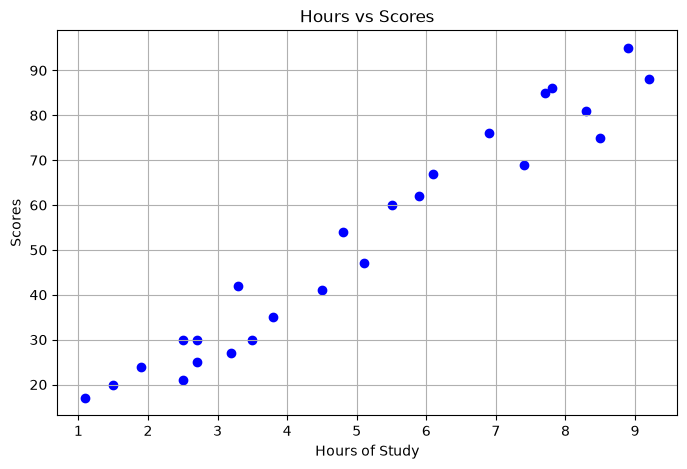

In [19]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.scatter(df['Hours'],df['Scores'],color='blue')
plt.title('Hours vs Scores')
plt.xlabel('Hours of Study')
plt.ylabel('Scores')
plt.grid(True)
plt.show()

X and Y

In [20]:
X=df[['Hours']]
Y=df['Scores']

In [21]:
print('X shape:', X.shape)
print('y shape:', Y.shape)

X shape: (25, 1)
y shape: (25,)


In [22]:
print('X', X.head(), '\n Y', Y.head())

X    Hours
0    2.5
1    5.1
2    3.2
3    8.5
4    3.5 
 Y 0    21
1    47
2    27
3    75
4    30
Name: Scores, dtype: int64


### Train-Test Split

In [23]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X,Y, test_size=0.2, random_state=42)
print('Train size:', X_train.shape[0])
print('Test size :', X_test.shape[0])

Train size: 20
Test size : 5


# fit linear regression model

In [24]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
# # convert X_train to 2D array
# X_train = X_train.values.reshape(-1, 1)
model.fit(X_train,Y_train)



,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[9.68]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Hours']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.827
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [25]:
print('Intercept (b0):', model.intercept_)
print('Slope (b1)    :', model.coef_[0])

Intercept (b0): 2.826892353899737
Slope (b1)    : 9.682078154455697


### Prediction

In [26]:
Y_pred = model.predict(X_test)
# Generate new table using the dictionary
results = pd.DataFrame({
    'Hours': X_test['Hours'],
    'Actual Scores': Y_test,
    'Predicted Scores': Y_pred.round(2)
}) 
results

,Hours,Actual Scores,Predicted Scores
8,8.3,81,83.19
16,2.5,30,27.03
0,2.5,21,27.03
23,6.9,76,69.63
11,5.9,62,59.95


### evaluate the model


In [27]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae=mean_absolute_error(Y_test,Y_pred)
mse=mean_squared_error(Y_test,Y_pred)
rmse=np.sqrt(mse)
r2=r2_score(Y_test,Y_pred)

In [28]:
print(f'MAE  : {mae:,.2f}')
print(f'MSE  : {mse:,.2f}')
print(f'RMSE : {rmse:,.2f}')
print(f'R2   : {r2:.4f}')

MAE  : 3.92
MSE  : 18.94
RMSE : 4.35
R2   : 0.9678


### checking Overfitting

In [29]:
train_r2 = model.score(X_train, Y_train)
test_r2 = model.score(X_test, Y_test)

print(f'Train R2: {train_r2:.4f}')
print(f'Test  R2: {test_r2:.4f}')

Train R2: 0.9491
Test  R2: 0.9678


### Graph 

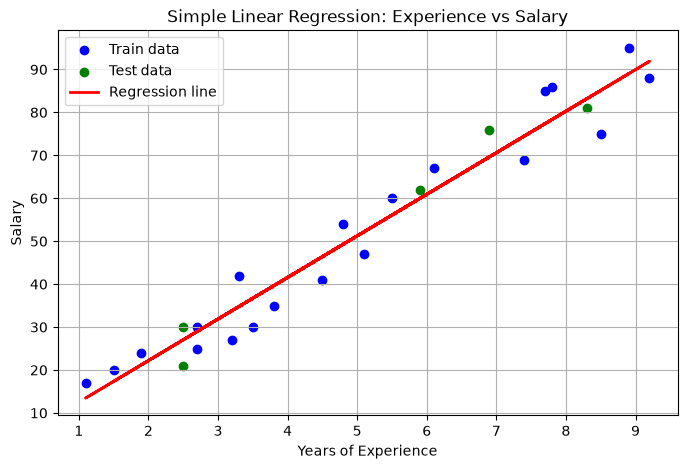

In [30]:
plt.figure(figsize=(8, 5))
plt.scatter(X_train, Y_train, color='blue', label='Train data')
plt.scatter(X_test, Y_test, color='green', label='Test data')
plt.plot(X, model.predict(X), color='red', linewidth=2, label='Regression line')
plt.title('Simple Linear Regression: Experience vs Salary')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.legend()
plt.grid(True)
plt.show()